In [1]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

img = nib.load("data/FBIRN_QA_fMRI_flip77_13.nii.gz")
fq, ph, sl = img.header.get_dim_info()
data = img.get_fdata()

# Discard first two time points
data = data[:,:,:,2:]
np.info(data)

class:  ndarray
shape:  (64, 64, 30, 198)
strides:  (8, 512, 32768, 983040)
itemsize:  8
aligned:  True
contiguous:  False
fortran:  True
data pointer: 0x72794b0a8010
byteorder:  little
byteswap:  False
type: float64


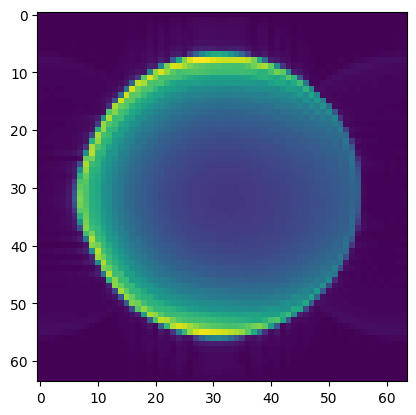

In [2]:
signal = data.mean(axis=-1)
plt.imshow(signal[:,:,15])

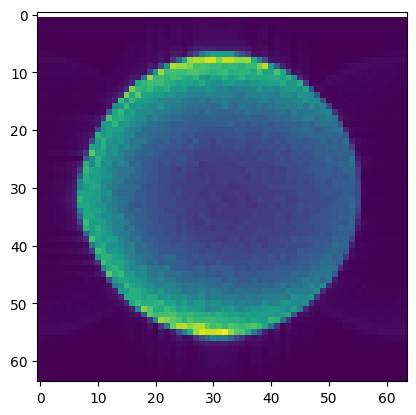

In [3]:
def poly_detrend(data, deg=2):
    nt = data.shape[-1]
    x = np.arange(nt)
    y = np.reshape(data,(-1,nt))
    c = np.polynomial.legendre.legfit(x, y.T, deg)
    fit = np.polynomial.legendre.legval(x, c)
    return np.reshape(y - fit, data.shape)

resid = poly_detrend(data)
noise = np.std(resid, axis=-1, mean=0, ddof=3)
noise = np.ma.masked_equal(noise, 0)

sfnr = signal/noise

#plt.plot((data-det).mean(axis=-1)[:,:,15])
plt.imshow(sfnr[:,:,15])

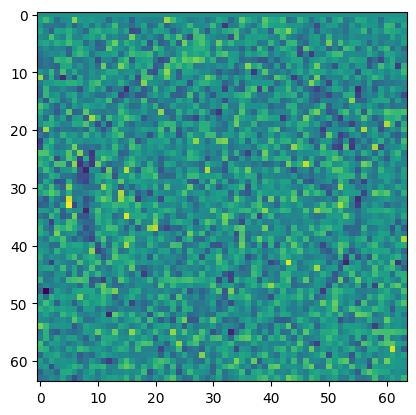

In [4]:
m1 = data[:,:,:,::2].mean(axis=-1)
m2 = data[:,:,:,1::2].mean(axis=-1)

plt.imshow((m2-m1)[:,:,15])

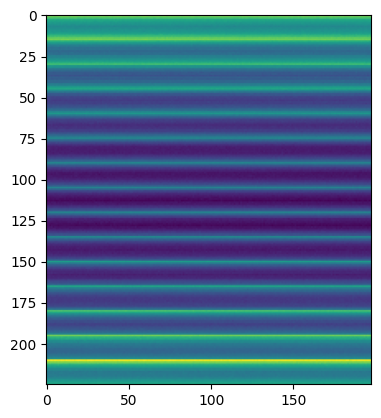

In [9]:
core = np.reshape(data[25:40,25:40,15,:],(-1,data.shape[-1]))
plt.imshow(core)

array([ 1,  3,  5,  7,  9, 11, 13, 15, 17, 19, 21])

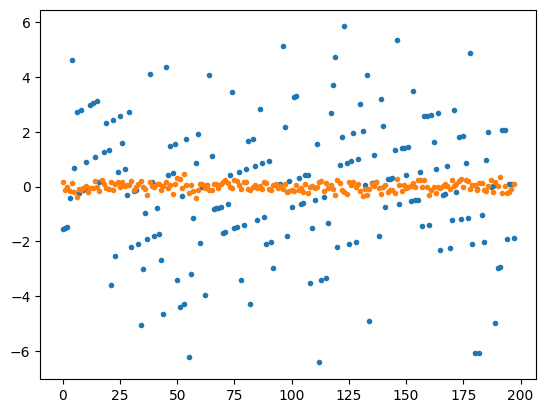

In [91]:
def extract_roi(data, w, center=None):
    nxy, nzt = data.shape[:2], data.shape[2:]
    center = center or [i/2 for i in nxy]
    data = data.reshape((*nxy, -1))
    i, j = [int((c - w - 1) / 2) for c in center]
    return data[i:i+w,j:j+w,:].reshape((w*w,*nzt))

def fbirn_cv(data, w, center=None):
    extract_roi(data, w, center=center)
    c = np.polynomial.legendre.legfit(x, y.T, deg)
    fit = np.polynomial.legendre.legval(x, c)
    pass

sl = data[:,:,15,:]
n = np.arange(1,23,2, dtype=int)
f = np.array([extract_roi(sl, w).mean(axis=0) for w in n])
g = poly_detrend(f)
cv = g.std(axis=-1, mean=0)/f.mean(axis=-1)

plt.plot(g[0,:],'.')
plt.plot(g[-1,:],'.')
n

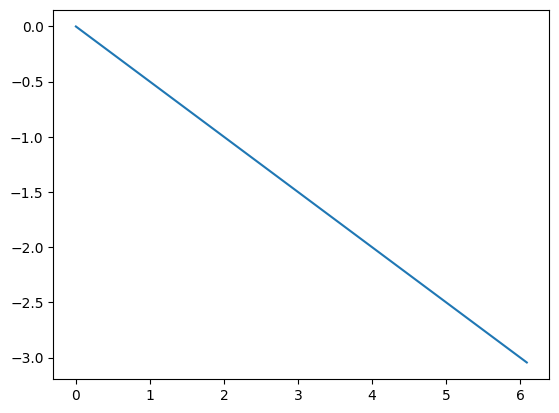

In [92]:
plt.plot(np.log(n*n), np.log(1/np.sqrt(n*n)))

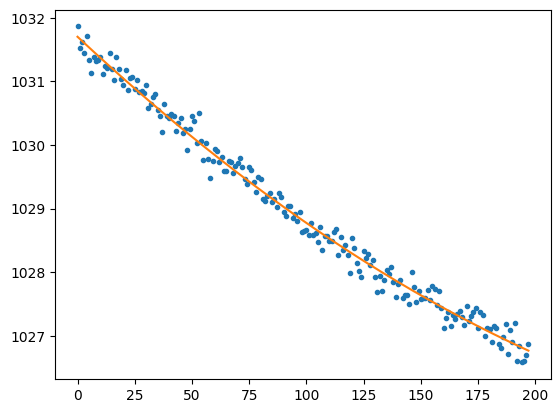

In [115]:
x = np.arange(198)
y = f[-1,:]
plt.plot(x, y,'.')
c = np.polynomial.legendre.legfit(x, y.T, 2)
fit = np.polynomial.legendre.legval(x, c)
plt.plot(fit)

In [118]:
np.std(y - fit, mean=0) / fit.mean()

np.float64(0.0001492100958526826)

In [119]:
cv

array([0.00086734, 0.0002831 , 0.0002558 , 0.00025224, 0.00023928,
       0.00023041, 0.00020662, 0.00018005, 0.00016862, 0.0001546 ,
       0.00014921])

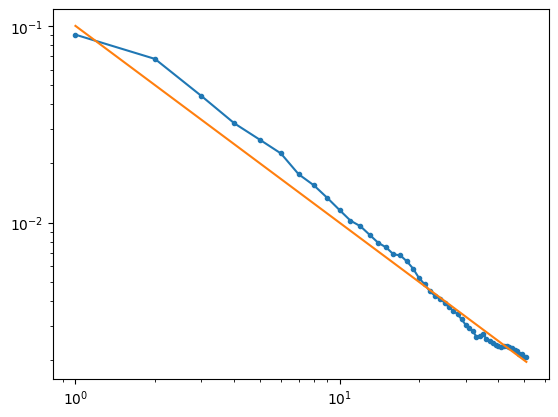

In [185]:
N = 51
data = np.random.normal(10, 1, (N*N,198))
n = range(N)
rois = np.array([np.mean(data[:i*i+1,:],axis=0) for i in n])
cv = [np.std(rois[i,:])/np.mean(rois[i,:]) for i in n]
n = np.array(n, dtype=float) + 1
ideal = np.sqrt(1/(n*n))

CV0 = 0.1

plt.loglog(n,cv, '.-')
plt.loglog(n,CV0*ideal)

np.float64(0.09978565541425934)